## Author: Gabriel Vance
## Class: DSC640 - Data Presentation & Visualization 
## Professor: Benjamin Schneider
## Date: October 3, 2025

# Purpose: This notebook performs the tasks for Week 3 & 4 assignment.

### Call to action: Transparency is important in politics. The public must be made aware of the visitors to the White House. To encourage this policy, we will be releasing reports explaining the trends of visitors to the White House over time.


### Audience: The audience will be the general public as this is a call to action for them to write their representatives to encourage transparency in government.
### Purpose: The purpose is to inform the public of the trends in visitors to the White House over time. We are advocating for the continuance of this policy and will demonstrate the data that is at risk of being hidden.
### Medium: The medium will be a series of visualizations that can be shared on social media and in news articles.

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")
import matplotlib.ticker as ticker
import calendar

# # Ensure that all code cells are fully visible without scrolling
from IPython.display import display, HTML

display(HTML('''
<style>
div.CodeMirror pre {
    white-space: pre !important;
}
</style>
'''))

### Reading in data
I merged the datasets together into a single CSV file. We'll read in the data and continue the analysis.

In [37]:
# Load the cleaned merged dataset
merged_df = pd.read_csv('merged_white_house_visitors_cleaned.csv')

Take the appointment dtg and extract the year and month, for future analysis.

In [38]:
# Extract year and month from the appointment_start_date
merged_df['year_of_visit'] = pd.to_datetime(merged_df['appointment_start_date'], errors='coerce').dt.year
merged_df['month_of_visit'] = pd.to_datetime(merged_df['appointment_start_date'], errors='coerce').dt.month

In [39]:
# Note: some of the dates are NaT. For analysis pertaining to dates, we will need to drop those rows. Otherwise, we can keep them.
print("Min appointment_start_date:", merged_df['appointment_start_date'].min())
print("Max appointment_start_date:", merged_df['appointment_start_date'].max())

Min appointment_start_date: 2021-04-01
Max appointment_start_date: NaT


### Visualization 1. Bar Chart showing the top 10 guests by number of visits.

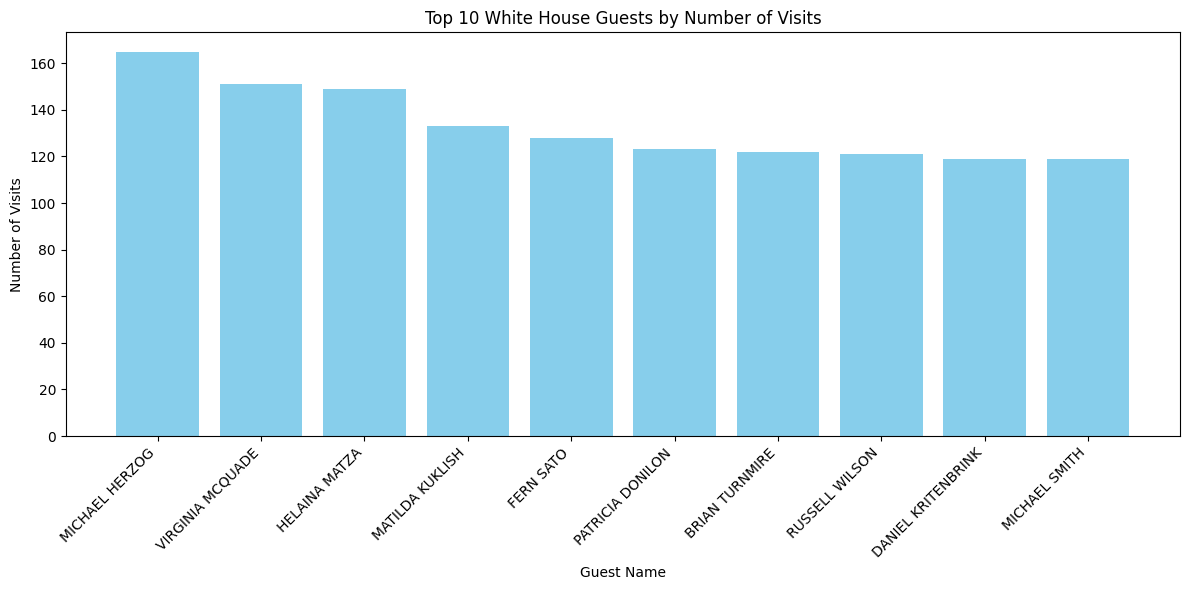

In [40]:
# Count visits for each guest (first_name + last_name)
guest_counts = merged_df.groupby(['first_name', 'last_name']).size().sort_values(ascending=False)

# Get top 10 guests
top_10_guests = guest_counts.head(10)

# Prepare labels for x-axis
labels = [f"{fn} {ln}" for fn, ln in top_10_guests.index]

plt.figure(figsize=(12, 6))
plt.bar(labels, top_10_guests.values, color='skyblue')
plt.xlabel('Guest Name')
plt.ylabel('Number of Visits')
plt.title('Top 10 White House Guests by Number of Visits')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Dropping rows with NaT in appointment_start_date for date analysis, as we stated earlier.

In [41]:
merged_df_without_na = merged_df[merged_df['appointment_start_date'] != 'NaT']

### Visualization 2. Step Chart showing the number of visits per month over time.

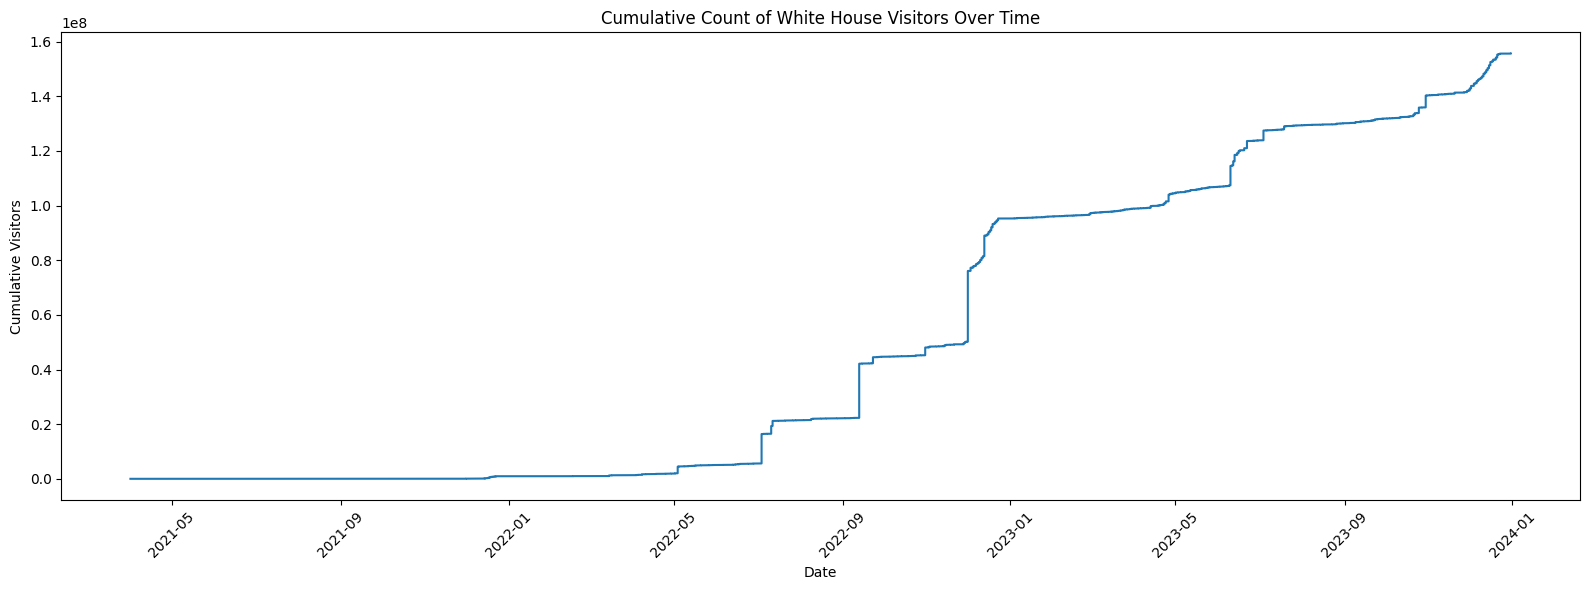

In [42]:
# Step chart: Cumulative count of visitors over time
appointment_dates_dt = pd.to_datetime(merged_df_without_na['appointment_start_date'], errors='coerce')
cumulative_visitors = merged_df_without_na.groupby(appointment_dates_dt.dt.date)['total_people'].sum().cumsum()

plt.figure(figsize=(16,6))
plt.step(cumulative_visitors.index, cumulative_visitors.values, where='post')
plt.xlabel('Date')
plt.ylabel('Cumulative Visitors')
plt.title('Cumulative Count of White House Visitors Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualization 3. Stacked Bar Chart showing the number of visits from the top 5 visitors per year.

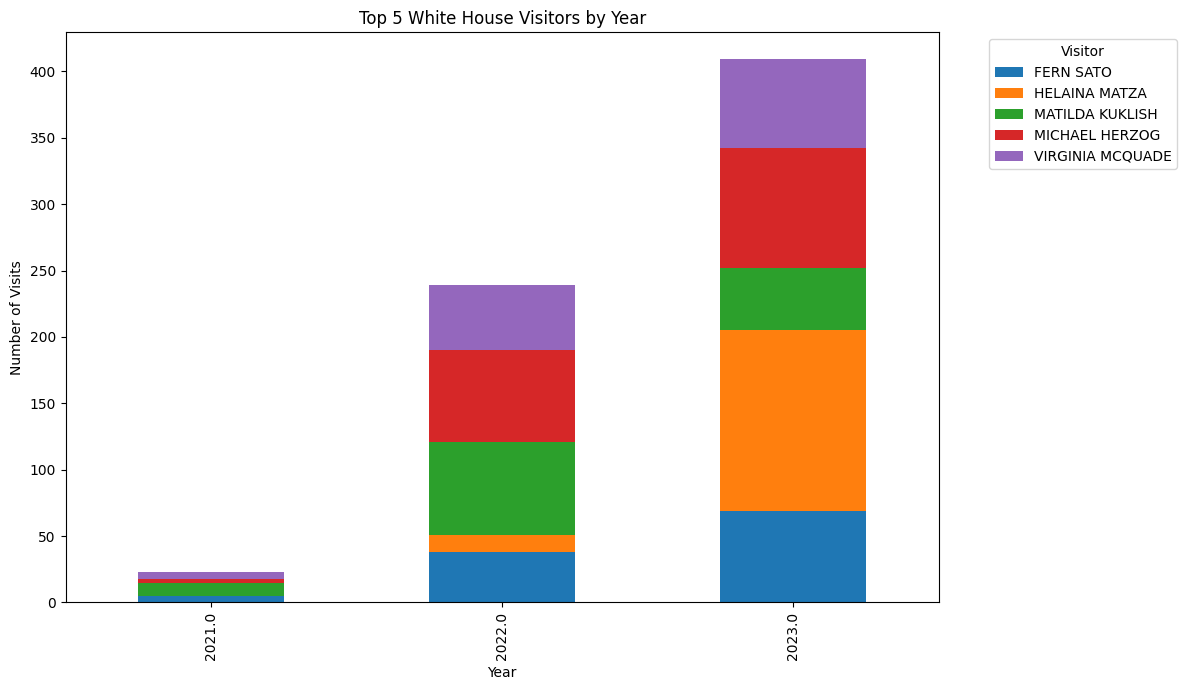

In [43]:
# Get top 5 visitors overall
top_5 = guest_counts.head(5)
top_5_names = set(top_5.index)

# Create a new column for visitor name
merged_df['visitor_name'] = merged_df['first_name'].str.strip() + ' ' + merged_df['last_name'].str.strip()

# Filter for only top 5 visitors
valid_top5 = merged_df[merged_df.set_index(['first_name', 'last_name']).index.isin(top_5_names)]

# Group by year_of_visit and visitor_name, count rows
grouped = valid_top5.groupby(['year_of_visit', 'visitor_name']).size().unstack(fill_value=0)

# Plot stacked bar chart
grouped.plot(kind='bar', stacked=True, figsize=(12,7))
plt.xlabel('Year')
plt.ylabel('Number of Visits')
plt.title('Top 5 White House Visitors by Year')
plt.legend(title='Visitor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### Visualization 4. Pie chart showing the months visited

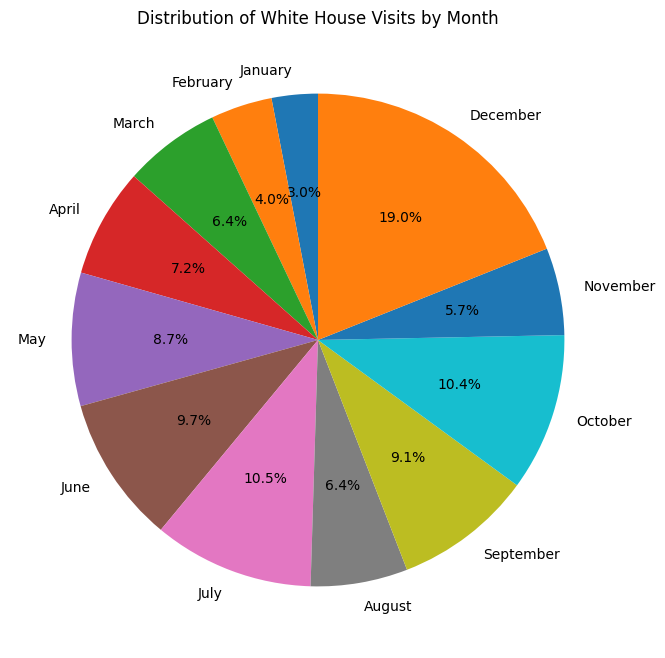

In [44]:

# Pie chart of visits by month with month names
month_counts = merged_df['month_of_visit'].value_counts().sort_index()
month_labels = [calendar.month_name[int(m)] for m in month_counts.index if pd.notnull(m)]

plt.figure(figsize=(8,8))
plt.pie(month_counts, labels=month_labels, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of White House Visits by Month')
plt.show()

### Visualization 5. Line chart showing the average number of visitors over time, grouped by month

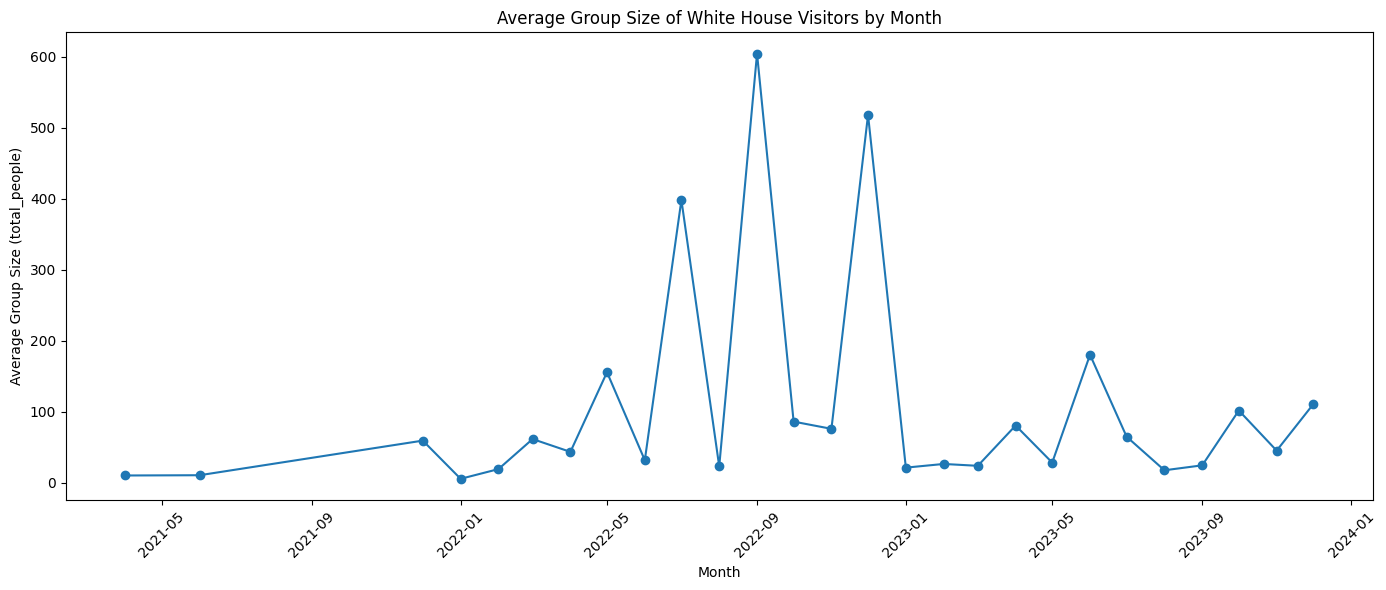

In [45]:
# Group by year and month, take average total_people per month
monthly_avg = merged_df_without_na.groupby(
    [merged_df_without_na['year_of_visit'], merged_df_without_na['month_of_visit']]
)['total_people'].mean()

# Create a datetime index for plotting
monthly_avg.index = [pd.Timestamp(year=int(y), month=int(m), day=1)
                     for y, m in monthly_avg.index]

plt.figure(figsize=(14,6))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o')
plt.xlabel('Month')
plt.ylabel('Average Group Size (total_people)')
plt.title('Average Group Size of White House Visitors by Month')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualization 6. Bar chart showing the location of the appointment

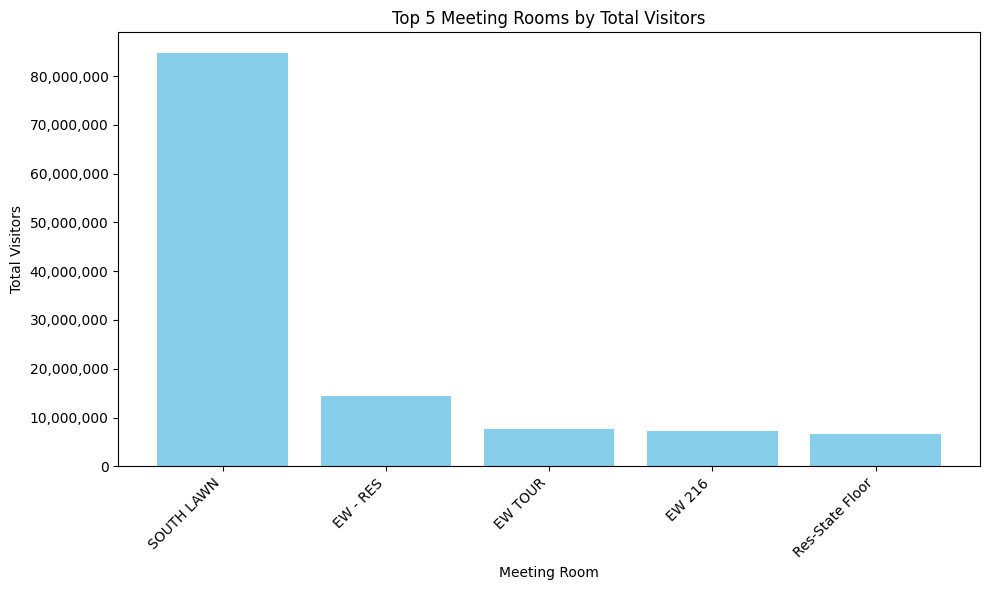

In [46]:

# Sum total_people for each meeting_room
room_sums = merged_df_without_na.groupby('meeting_room')['total_people'].sum().sort_values(ascending=False)

# Top 5 meeting rooms
top_5_rooms = room_sums.head(5)

plt.figure(figsize=(10,6))
plt.bar(top_5_rooms.index, top_5_rooms.values, color='skyblue')

plt.xlabel('Meeting Room')
plt.ylabel('Total Visitors')
plt.title('Top 5 Meeting Rooms by Total Visitors')
plt.xticks(rotation=45, ha='right')

# Format y-axis with commas instead of scientific notation
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))

plt.tight_layout()
plt.show()

# Summary

Purpose/Call to Arms - Transparency is important in politics. The public must be made aware of the visitors to the White House. To encourage this policy, we've done a deep dive on the data and are calling for the current administration to continue this policy of transparency. Journalists and the public should remind their elected officials that transparency is a key part of democracy.

We can see that most visits occur during holidays, such as the 4th of July and Christmas. This mostly aligns with nature of public visits to the White House. We also see much smaller numbers for 2021, despite this being the first year of the presidency. This is likely due to the COVID-19 pandemic, which limited public gatherings and events. The low number of visits shows the administrations commitment to public health and safety during the pandemic.

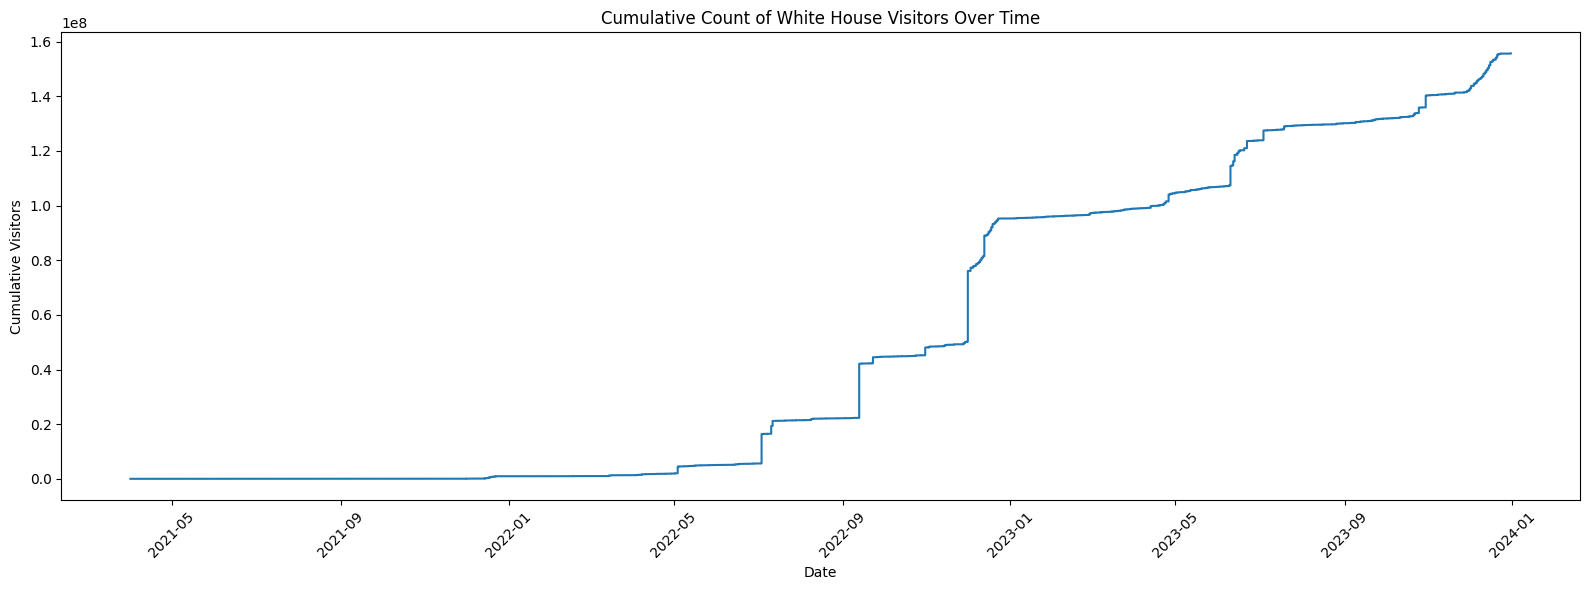

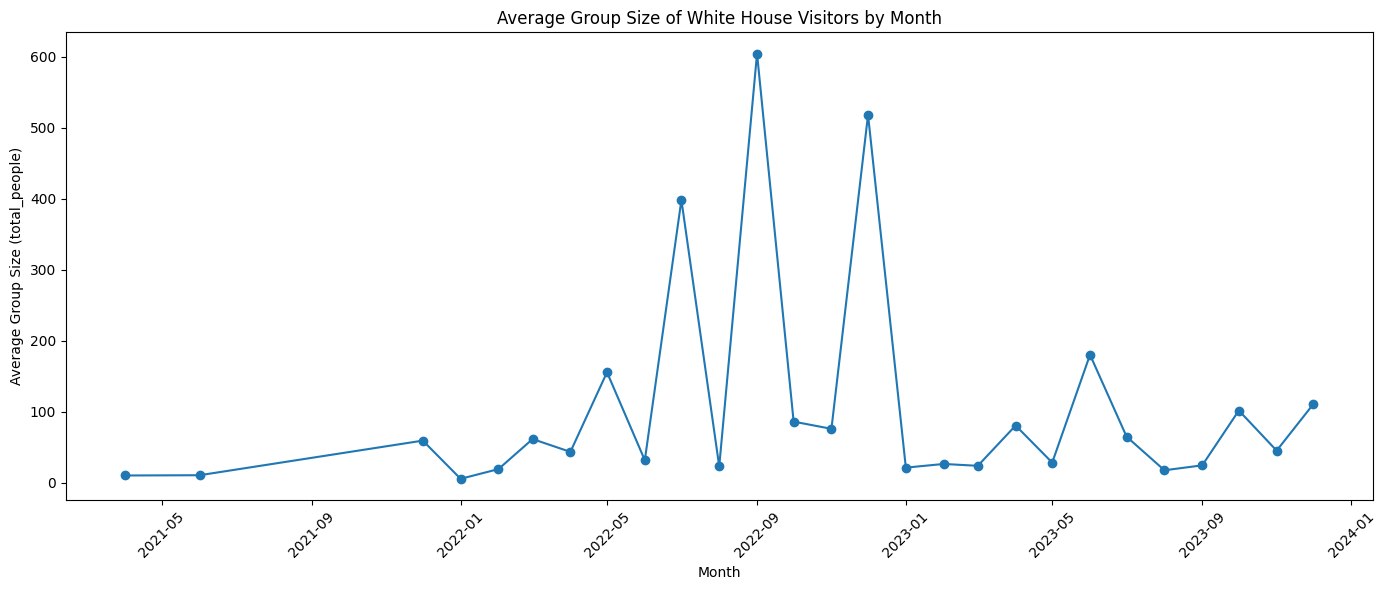

When the gathering did occur, the overwhelming majority of visitors went to South Lawn, which is the main area for public events and gatherings. This shows that the administration is committed to hosting public events and gatherings, despite the challenges posed by the pandemic. Additionally, the East Wing shows a significant number of visits, especially for tours.

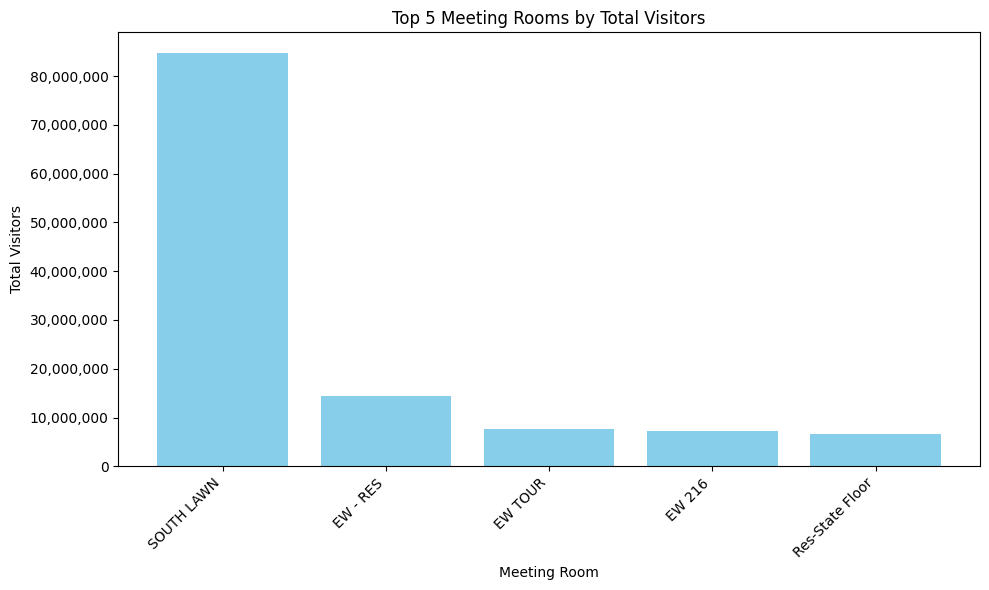

A common worry amongst the public is who is visiting the White House. The fact that the visitor logs are public means the administration is not trying to hide the visitors, especially those with political connections. We can create charts showing the names of these individuals and how often they frequented the White House.

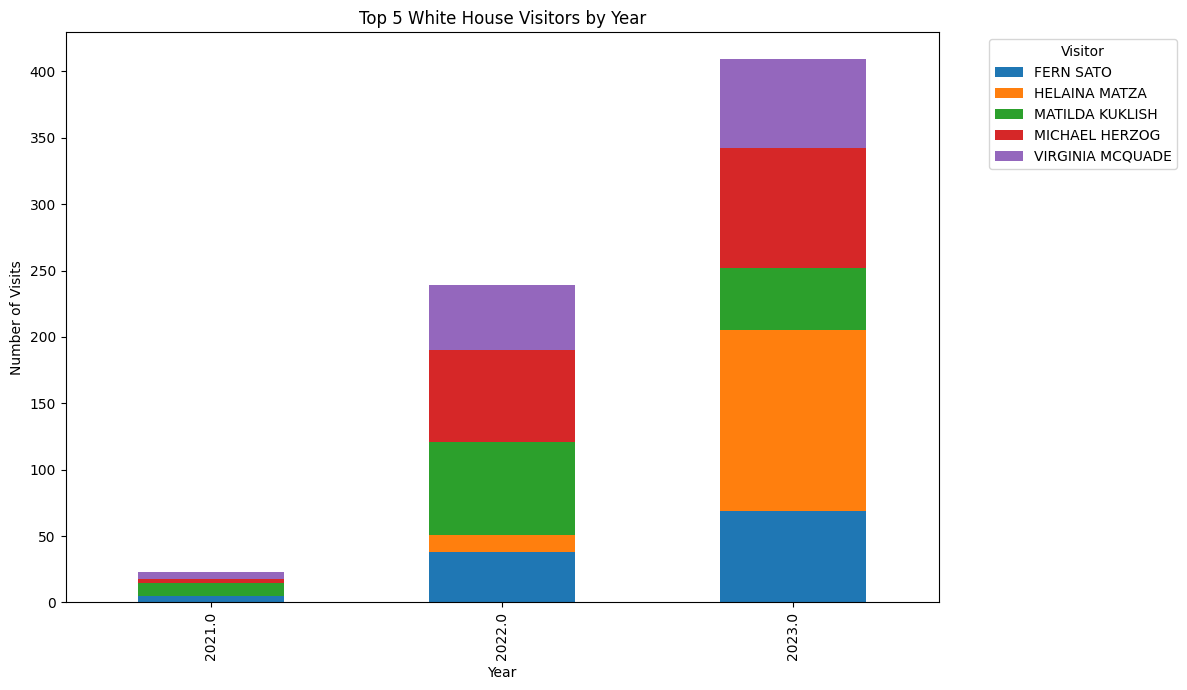

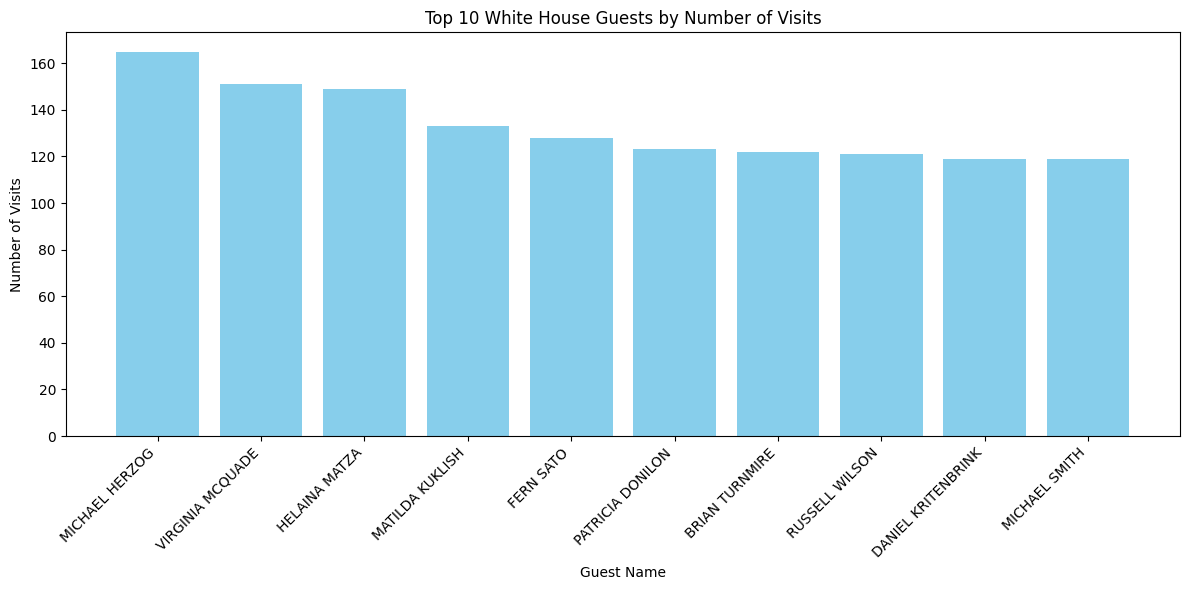

The act of releasing the visitor logs instills public trust with the American people. College students, pundits, and data scientists find the data quite valuable and it's a nice a handshake between the government and its people. It's a terrible shame that the current administration has stopped this practice. We call on them to reinstate the practice of releasing the visitor logs, so the public can continue to hold their elected officials accountable.